# 09 — Toronto thermal accessibility × Bike Share response

## Purpose

This notebook links the modeled accessibility response from Notebook 07 to the
observed Bike Share heat-event comparison from Notebook 08.

The analysis is deliberately **exploratory**.

Bike Share activity is not a direct validation of pedestrian accessibility.
Instead, the question is:

> Do Bike Share stations in locations with larger modeled heat-conditioned
> accessibility loss also show stronger heat-event deviations in observed
> active-mobility activity?

### Main modeled signal

Notebook 07 showed:

- normal mean reachable transit stops: about 41.9;
- absolute-threshold λ = 0.05 mean: about 31.0;
- mean absolute accessibility loss: about 25.6%;
- relative-median λ = 0.05 mean loss: about 0.23%.

Because the relative formulation is almost inert at λ = 0.05, this notebook uses
the **absolute 32°C model at λ = 0.05 as the primary accessibility signal**.

The relative model is retained only as an exploratory sensitivity field.

### Observed Bike Share signal

Station-level Bike Share activity on:

- 25 July 2025 — heat-event Friday

is compared with:

- 18 July 2025 — matched Friday before;
- 1 August 2025 — matched Friday after.

To reduce the risk of interpreting a system-wide ridership shift as a local thermal
response, station changes are also calculated relative to the citywide change.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and paths

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests

from scipy.spatial import cKDTree

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

ACCESSIBILITY_DIR = (
    TORONTO_OUTPUTS
    / "accessibility"
)

BIKE_INTERIM = (
    TORONTO_INTERIM
    / "bikeshare"
)

BIKE_OUTPUTS = (
    TORONTO_OUTPUTS
    / "bikeshare"
)

LINK_OUTPUTS = (
    TORONTO_OUTPUTS
    / "thermal_accessibility_bikeshare"
)

LINK_OUTPUTS.mkdir(
    parents=True,
    exist_ok=True,
)

ACCESS_GPKG = (
    ACCESSIBILITY_DIR
    / "toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg"
)

STUDY_TRIPS_PATH = (
    BIKE_INTERIM
    / "toronto_bikeshare_heat_reference_days.parquet"
)

print("Accessibility file:", ACCESS_GPKG)
print("Bike Share trips:", STUDY_TRIPS_PATH)

Accessibility file: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/accessibility/toronto_origin_accessibility_absolute_vs_relative_lambda_005.gpkg
Bike Share trips: /scratch/project_2010417/paper3/heat-conditioned-accessibility/data/toronto/interim/bikeshare/toronto_bikeshare_heat_reference_days.parquet


## 2. Load origin-level accessibility results from Notebook 07

In [2]:
if not ACCESS_GPKG.exists():
    raise FileNotFoundError(
        f"Accessibility output not found: {ACCESS_GPKG}"
    )

origins = gpd.read_file(
    ACCESS_GPKG
)

numeric_cols = [
    "normal_access",
    "absolute_access",
    "relative_access",
    "absolute_loss_pct",
    "relative_loss_pct",
]

for column in numeric_cols:
    if column in origins.columns:
        origins[column] = pd.to_numeric(
            origins[column],
            errors="coerce",
        )

display(
    origins[
        [
            column
            for column in numeric_cols
            if column in origins.columns
        ]
    ].describe()
)

print("Origins:", len(origins))
print("CRS:", origins.crs)

,normal_access,absolute_access,relative_access,absolute_loss_pct,relative_loss_pct
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,41.880000,30.960000,41.820000,25.616491,0.227273
std,14.166128,10.044716,14.232314,9.135791,0.918320
min,9.000000,4.000000,9.000000,5.555556,0.000000
25%,31.000000,23.250000,31.000000,19.473684,0.000000
50%,42.500000,31.500000,42.500000,25.806452,0.000000
75%,53.750000,37.500000,53.750000,30.715812,0.000000
max,65.000000,51.000000,65.000000,55.555556,4.166667


Origins: 50
CRS: EPSG:32617


## 3. Load the Bike Share study-day trip extract from Notebook 08

In [3]:
if not STUDY_TRIPS_PATH.exists():
    raise FileNotFoundError(
        "Bike Share event/reference extract was not found. "
        "Run Notebook 08 first."
    )

trips = pd.read_parquet(
    STUDY_TRIPS_PATH
)

print(
    "Trips:",
    f"{len(trips):,}",
)

print(
    "Columns:",
    list(trips.columns),
)

Trips: 118,657
Columns: ['trip_id', 'duration_seconds', 'start_station_id', 'start_datetime', 'start_station_name', 'end_station_id', 'end_datetime', 'end_station_name', 'bike_id', 'user_type', 'bike_model', 'date', 'hour', 'start_station_id_join', 'end_station_id_join', 'day_type', 'is_afternoon', 'start_in_pilot', 'end_in_pilot', 'touches_pilot']


## 4. Standardize date and station-ID fields

In [4]:
EVENT_DATE = pd.Timestamp(
    "2025-07-25"
)

REFERENCE_DATES = [
    pd.Timestamp(
        "2025-07-18"
    ),
    pd.Timestamp(
        "2025-08-01"
    ),
]

if "date" not in trips.columns:
    raise RuntimeError(
        "Expected 'date' column was not found in Notebook 08 output."
    )

trips["date"] = pd.to_datetime(
    trips["date"],
    errors="coerce",
).dt.normalize()

if "start_station_id_join" not in trips.columns:
    raise RuntimeError(
        "Expected start_station_id_join column was not found. "
        "Notebook 08 must successfully identify station IDs first."
    )

trips[
    "start_station_id_join"
] = (
    trips[
        "start_station_id_join"
    ]
    .astype(str)
    .str.replace(
        r"\.0$",
        "",
        regex=True,
    )
    .str.strip()
)

## 5. Retrieve current Bike Share station coordinates

As in Notebook 08, current GBFS station coordinates are used as a practical
proof-of-concept spatial reference.

**Publication caveat:** historical July 2025 station coordinates should be
verified before any final inference.

In [5]:
GBFS_ROOT_CANDIDATES = [
    (
        "https://tor.publicbikesystem.net/"
        "ube/gbfs/v1/gbfs.json"
    ),
    (
        "https://tor.publicbikesystem.net/"
        "customer/gbfs/v2/gbfs.json"
    ),
]

gbfs_root = None
gbfs_root_url = None

for candidate in GBFS_ROOT_CANDIDATES:

    try:
        response = requests.get(
            candidate,
            timeout=30,
        )

        if response.ok:
            gbfs_root = response.json()
            gbfs_root_url = candidate
            break

    except Exception:
        pass

if gbfs_root is None:
    raise RuntimeError(
        "Could not retrieve Bike Share GBFS feed."
    )

print(
    "GBFS root:",
    gbfs_root_url,
)

GBFS root: https://tor.publicbikesystem.net/ube/gbfs/v1/gbfs.json


In [6]:
data_section = gbfs_root.get(
    "data",
    {}
)

if "en" in data_section:
    feeds = (
        data_section[
            "en"
        ].get(
            "feeds",
            []
        )
    )
else:
    feeds = (
        data_section.get(
            "feeds",
            []
        )
    )

station_info_url = None

for feed in feeds:
    if feed.get("name") == "station_information":
        station_info_url = feed.get("url")
        break

if station_info_url is None:
    raise RuntimeError(
        "GBFS station_information feed was not found."
    )

station_json = requests.get(
    station_info_url,
    timeout=30,
).json()

station_df = pd.DataFrame(
    station_json[
        "data"
    ][
        "stations"
    ]
)

print(
    "Stations in current GBFS:",
    len(station_df),
)

Stations in current GBFS: 1072


## 6. Build station GeoDataFrame

In [7]:
required_station_cols = {
    "station_id",
    "lat",
    "lon",
}

if not required_station_cols.issubset(
    station_df.columns
):
    raise RuntimeError(
        "GBFS station information is missing station_id/lat/lon."
    )

station_df[
    "station_id_join"
] = (
    station_df[
        "station_id"
    ]
    .astype(str)
    .str.strip()
)

stations = gpd.GeoDataFrame(
    station_df,
    geometry=gpd.points_from_xy(
        station_df["lon"],
        station_df["lat"],
    ),
    crs=4326,
).to_crs(
    origins.crs
)

print(
    "Station CRS:",
    stations.crs,
)

Station CRS: EPSG:32617


## 7. Recreate the U of T pilot using accessibility-origin extent

We retain only stations in the same local thermal-study domain.

In [8]:
pilot_polygon = (
    origins.geometry
    .union_all()
    .convex_hull
    .buffer(
        150
    )
)

pilot_stations = stations[
    stations.geometry.within(
        pilot_polygon
    )
    |
    stations.geometry.touches(
        pilot_polygon
    )
].copy()

print(
    "Stations in accessibility pilot:",
    len(pilot_stations),
)

Stations in accessibility pilot: 75


## 8. Calculate citywide event/reference trip-start change

This becomes the system-wide background change against which local station
deviations are compared.

In [9]:
city_daily = (
    trips
    .groupby(
        "date"
    )
    .size()
    .rename(
        "trip_starts"
    )
)

city_event = float(
    city_daily.get(
        EVENT_DATE,
        np.nan,
    )
)

city_reference_values = [
    city_daily.get(
        date,
        np.nan,
    )
    for date in REFERENCE_DATES
]

city_reference_mean = float(
    np.nanmean(
        city_reference_values
    )
)

city_ratio = (
    city_event
    / city_reference_mean
)

city_change_pct = (
    (
        city_ratio
        - 1
    )
    * 100
)

print(
    "City event trips:",
    city_event,
)

print(
    "City reference mean:",
    city_reference_mean,
)

print(
    "Citywide event/reference ratio:",
    round(
        city_ratio,
        4,
    ),
)

print(
    "Citywide change (%):",
    round(
        city_change_pct,
        2,
    ),
)

City event trips: 37683.0
City reference mean: 40487.0
Citywide event/reference ratio: 0.9307
Citywide change (%): -6.93


## 9. Calculate station-level event/reference trip-start activity

A minimum baseline activity filter is applied later to avoid unstable percentage
changes from stations with very few trips.

In [10]:
station_day = (
    trips
    .groupby(
        [
            "start_station_id_join",
            "date",
        ]
    )
    .size()
    .rename(
        "trip_starts"
    )
    .reset_index()
)

station_pivot = (
    station_day
    .pivot_table(
        index="start_station_id_join",
        columns="date",
        values="trip_starts",
        fill_value=0,
    )
)

for date in [
    EVENT_DATE,
    *REFERENCE_DATES,
]:
    if date not in station_pivot.columns:
        station_pivot[date] = 0

station_pivot[
    "reference_mean"
] = station_pivot[
    REFERENCE_DATES
].mean(
    axis=1
)

station_pivot[
    "event"
] = station_pivot[
    EVENT_DATE
]

station_pivot[
    "raw_change_pct"
] = np.where(
    station_pivot[
        "reference_mean"
    ] > 0,
    (
        station_pivot[
            "event"
        ]
        - station_pivot[
            "reference_mean"
        ]
    )
    / station_pivot[
        "reference_mean"
    ]
    * 100,
    np.nan,
)

display(
    station_pivot[
        [
            "reference_mean",
            "event",
            "raw_change_pct",
        ]
    ].describe()
)

date,reference_mean,event,raw_change_pct
count,928.000000,928.000000,920.000000
mean,43.628233,40.606681,-2.451624
std,55.158962,51.050955,61.659926
min,0.000000,0.000000,-100.000000
25%,7.000000,6.000000,-27.272727
50%,25.000000,23.000000,-7.692308
75%,63.000000,58.250000,11.445867
max,835.500000,775.000000,500.000000


## 10. Calculate a citywide-adjusted station response

We use a log rate ratio:

\[
R_s
=
\log
\left(
rac{Event_s+0.5}{Reference_s+0.5}
ight)
-
\log
\left(
rac{Event_{city}+0.5}{Reference_{city}+0.5}
ight)
\]

Interpretation:

- \(R_s < 0\): station activity declined more than the citywide background;
- \(R_s > 0\): station activity performed better than the citywide background.

The 0.5 pseudocount prevents division problems at zero.

In [11]:
PSEUDOCOUNT = 0.5

city_log_ratio = np.log(
    (
        city_event
        + PSEUDOCOUNT
    )
    /
    (
        city_reference_mean
        + PSEUDOCOUNT
    )
)

station_pivot[
    "station_log_ratio"
] = np.log(
    (
        station_pivot[
            "event"
        ]
        + PSEUDOCOUNT
    )
    /
    (
        station_pivot[
            "reference_mean"
        ]
        + PSEUDOCOUNT
    )
)

station_pivot[
    "city_adjusted_log_response"
] = (
    station_pivot[
        "station_log_ratio"
    ]
    - city_log_ratio
)

station_activity = (
    station_pivot
    .reset_index()
)

display(
    station_activity[
        [
            "reference_mean",
            "event",
            "raw_change_pct",
            "city_adjusted_log_response",
        ]
    ].describe()
)

date,reference_mean,event,raw_change_pct,city_adjusted_log_response
count,928.000000,928.000000,920.000000,928.000000
mean,43.628233,40.606681,-2.451624,-0.076232
std,55.158962,51.050955,61.659926,0.578580
min,0.000000,0.000000,-100.000000,-4.102616
25%,7.000000,6.000000,-27.272727,-0.222246
50%,25.000000,23.000000,-7.692308,-0.002337
75%,63.000000,58.250000,11.445867,0.187700
max,835.500000,775.000000,500.000000,1.681209


## 11. Join activity measures to pilot stations

In [12]:
pilot_stations = (
    pilot_stations
    .merge(
        station_activity,
        left_on="station_id_join",
        right_on="start_station_id_join",
        how="left",
    )
)

print(
    "Pilot stations with activity data:",
    pilot_stations[
        "reference_mean"
    ].notna().sum(),
)

Pilot stations with activity data: 69


## 12. Apply a minimum baseline-activity filter

Very low-volume stations can produce extreme percentage changes from only one or
two trips.

For the proof-of-concept we require:

**mean reference-day trip starts ≥ 10**

In [13]:
MIN_REFERENCE_TRIPS = 10

analysis_stations = (
    pilot_stations[
        pilot_stations[
            "reference_mean"
        ] >= MIN_REFERENCE_TRIPS
    ]
    .copy()
)

print(
    "Stations before filter:",
    len(pilot_stations),
)

print(
    "Stations after baseline filter:",
    len(analysis_stations),
)

Stations before filter: 75
Stations after baseline filter: 69


## 13. Map station-level observed response

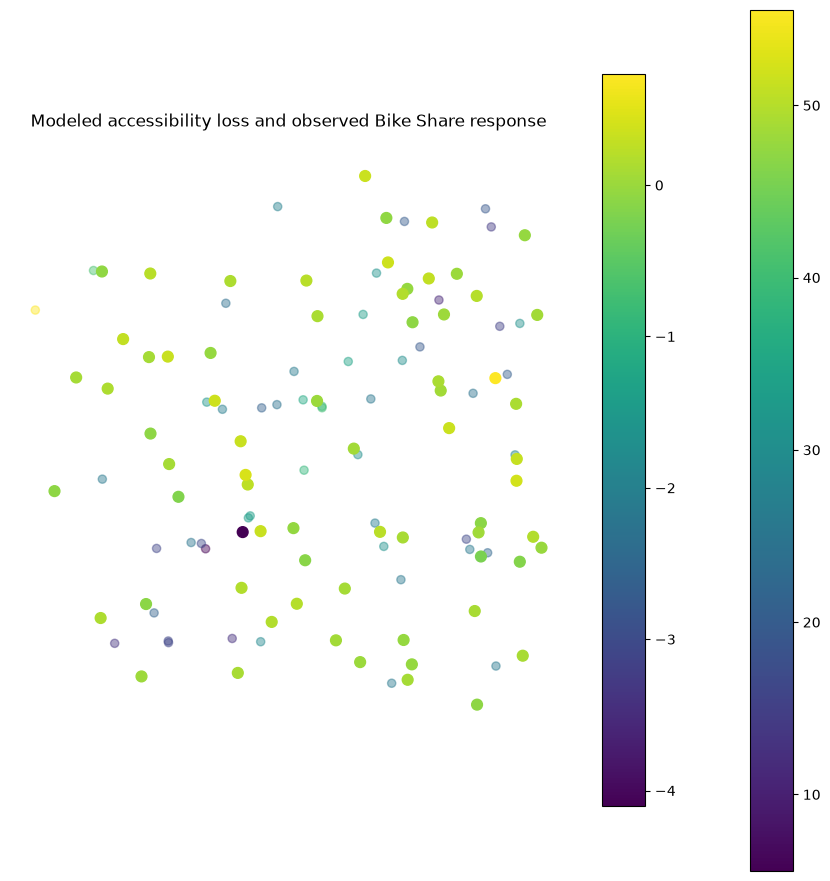

In [14]:
fig, ax = plt.subplots(
    figsize=(9, 9)
)

origins.plot(
    ax=ax,
    column="absolute_loss_pct",
    markersize=35,
    alpha=0.45,
    legend=True,
)

analysis_stations.plot(
    ax=ax,
    column="city_adjusted_log_response",
    markersize=60,
    legend=True,
)

ax.set_title(
    "Modeled accessibility loss and observed Bike Share response"
)

ax.set_axis_off()

plt.tight_layout()
plt.show()

## 14. Transfer modeled accessibility loss to station locations

Notebook 07 uses 50 sampled origin nodes, while Bike Share observations occur at
station locations.

We therefore estimate the local modeled accessibility signal at each Bike Share
station using **inverse-distance weighting of the five nearest accessibility
origins**.

This avoids assigning each station to a single arbitrary nearest origin.

In [15]:
K_NEAREST = 5
EPSILON_M = 1.0

origin_xy = np.column_stack(
    [
        origins.geometry.x.to_numpy(),
        origins.geometry.y.to_numpy(),
    ]
)

station_xy = np.column_stack(
    [
        analysis_stations.geometry.x.to_numpy(),
        analysis_stations.geometry.y.to_numpy(),
    ]
)

tree = cKDTree(
    origin_xy
)

distances, indices = tree.query(
    station_xy,
    k=min(
        K_NEAREST,
        len(origins),
    ),
)

if distances.ndim == 1:
    distances = distances[:, None]
    indices = indices[:, None]

weights = 1.0 / (
    distances
    + EPSILON_M
)

weights = (
    weights
    / weights.sum(
        axis=1,
        keepdims=True,
    )
)

absolute_values = (
    origins[
        "absolute_loss_pct"
    ]
    .to_numpy()
)

relative_values = (
    origins[
        "relative_loss_pct"
    ]
    .to_numpy()
)

analysis_stations[
    "idw_absolute_loss_pct"
] = np.sum(
    weights
    * absolute_values[
        indices
    ],
    axis=1,
)

analysis_stations[
    "idw_relative_loss_pct"
] = np.sum(
    weights
    * relative_values[
        indices
    ],
    axis=1,
)

analysis_stations[
    "mean_origin_distance_m"
] = distances.mean(
    axis=1
)

display(
    analysis_stations[
        [
            "idw_absolute_loss_pct",
            "idw_relative_loss_pct",
            "mean_origin_distance_m",
        ]
    ].describe()
)

,idw_absolute_loss_pct,idw_relative_loss_pct,mean_origin_distance_m
count,69.000000,69.000000,69.000000
mean,25.395457,0.240012,295.882048
std,5.624058,0.647094,96.235139
min,14.809190,0.000000,91.047600
25%,22.367141,0.000000,217.487711
50%,25.299866,0.000000,274.439879
75%,27.667219,0.000000,362.833415
max,40.385356,2.904486,530.275906


## 15. Inspect modeled-vs-observed relationship

In [16]:
analysis_table = (
    analysis_stations[
        [
            "station_id_join",
            "reference_mean",
            "event",
            "raw_change_pct",
            "city_adjusted_log_response",
            "idw_absolute_loss_pct",
            "idw_relative_loss_pct",
            "mean_origin_distance_m",
            "geometry",
        ]
    ]
    .dropna(
        subset=[
            "city_adjusted_log_response",
            "idw_absolute_loss_pct",
        ]
    )
    .copy()
)

print(
    "Analysis stations:",
    len(
        analysis_table
    ),
)

display(
    analysis_table.head()
)

Analysis stations: 69


,station_id_join,reference_mean,event,raw_change_pct,city_adjusted_log_response,idw_absolute_loss_pct,idw_relative_loss_pct,mean_origin_distance_m,geometry
0,7001,130.0,137.0,5.384615,0.124022,23.495974,0.000000,242.292700,POINT (630325.291 4835931.717)
1,7002,107.5,97.0,-9.767442,-0.030508,25.976443,0.000000,269.556283,POINT (629030.258 4836147.38)
2,7003,25.0,25.0,0.000000,0.071771,34.402504,0.000000,409.465699,POINT (628769.218 4836129.804)
4,7006,239.0,198.0,-17.154812,-0.115993,21.966317,0.000000,215.987984,POINT (630175.861 4835426.037)
5,7007,123.0,135.0,9.756098,0.164501,17.257301,1.762998,245.293670,POINT (629161.43 4835151.834)


## 16. Correlation diagnostics

Pearson and Spearman correlations are both reported.

Given the small observational sample and non-experimental design, these are
exploratory diagnostics only.

In [17]:
pearson_absolute = (
    analysis_table[
        [
            "idw_absolute_loss_pct",
            "city_adjusted_log_response",
        ]
    ]
    .corr(
        method="pearson"
    )
    .iloc[
        0,
        1
    ]
)

spearman_absolute = (
    analysis_table[
        [
            "idw_absolute_loss_pct",
            "city_adjusted_log_response",
        ]
    ]
    .corr(
        method="spearman"
    )
    .iloc[
        0,
        1
    ]
)

pearson_relative = (
    analysis_table[
        [
            "idw_relative_loss_pct",
            "city_adjusted_log_response",
        ]
    ]
    .corr(
        method="pearson"
    )
    .iloc[
        0,
        1
    ]
)

spearman_relative = (
    analysis_table[
        [
            "idw_relative_loss_pct",
            "city_adjusted_log_response",
        ]
    ]
    .corr(
        method="spearman"
    )
    .iloc[
        0,
        1
    ]
)

print(
    "Absolute model Pearson:",
    pearson_absolute,
)

print(
    "Absolute model Spearman:",
    spearman_absolute,
)

print()

print(
    "Relative model Pearson:",
    pearson_relative,
)

print(
    "Relative model Spearman:",
    spearman_relative,
)

Absolute model Pearson: 0.010985456571131282
Absolute model Spearman: 0.19917975137615132

Relative model Pearson: 0.03282839272811859
Relative model Spearman: -0.05594233977313544


## 17. Scatter plot — primary absolute accessibility model

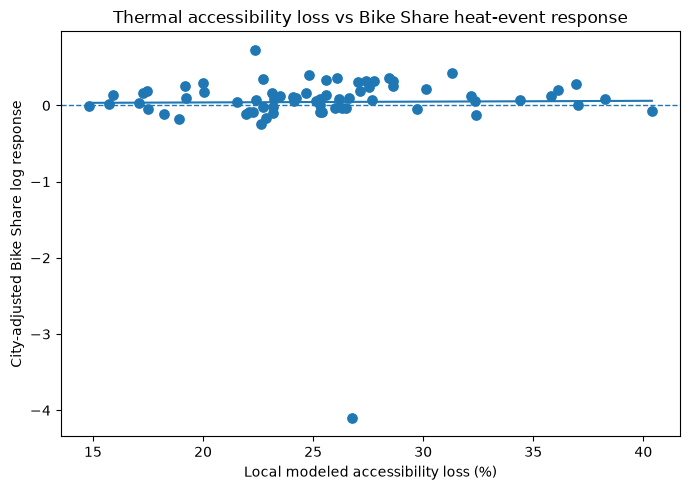

In [18]:
fig, ax = plt.subplots(
    figsize=(7, 5)
)

ax.scatter(
    analysis_table[
        "idw_absolute_loss_pct"
    ],
    analysis_table[
        "city_adjusted_log_response"
    ],
    s=45,
)

x = analysis_table[
    "idw_absolute_loss_pct"
].to_numpy()

y = analysis_table[
    "city_adjusted_log_response"
].to_numpy()

if (
    len(x) >= 2
    and np.isfinite(x).all()
    and np.isfinite(y).all()
    and np.nanstd(x) > 0
):

    slope, intercept = np.polyfit(
        x,
        y,
        1,
    )

    x_line = np.linspace(
        np.nanmin(x),
        np.nanmax(x),
        100,
    )

    y_line = (
        slope
        * x_line
        + intercept
    )

    ax.plot(
        x_line,
        y_line,
    )

ax.axhline(
    0,
    linestyle="--",
    linewidth=1,
)

ax.set_xlabel(
    "Local modeled accessibility loss (%)"
)

ax.set_ylabel(
    "City-adjusted Bike Share log response"
)

ax.set_title(
    "Thermal accessibility loss vs Bike Share heat-event response"
)

plt.tight_layout()
plt.show()

## 18. Compare high-loss and low-loss station groups

Stations are split at the median local modeled absolute accessibility loss.

In [19]:
median_loss = float(
    analysis_table[
        "idw_absolute_loss_pct"
    ].median()
)

analysis_table[
    "loss_group"
] = np.where(
    analysis_table[
        "idw_absolute_loss_pct"
    ] > median_loss,
    "higher_modeled_loss",
    "lower_modeled_loss",
)

group_summary = (
    analysis_table
    .groupby(
        "loss_group"
    )
    .agg(
        stations=(
            "station_id_join",
            "size",
        ),
        mean_modeled_loss_pct=(
            "idw_absolute_loss_pct",
            "mean",
        ),
        mean_raw_bikeshare_change_pct=(
            "raw_change_pct",
            "mean",
        ),
        mean_city_adjusted_response=(
            "city_adjusted_log_response",
            "mean",
        ),
        median_city_adjusted_response=(
            "city_adjusted_log_response",
            "median",
        ),
    )
    .reset_index()
)

display(
    group_summary
)

,loss_group,stations,mean_modeled_loss_pct,mean_raw_bikeshare_change_pct,mean_city_adjusted_response,median_city_adjusted_response
0,higher_modeled_loss,34,29.671905,4.843279,0.011254,0.10950
1,lower_modeled_loss,35,21.241193,2.483241,0.078099,0.06638


## 19. Afternoon-only sensitivity

The thermal simulation represents 15:00.

As an additional behavioral sensitivity test, we repeat the station-level activity
comparison using trip starts from **12:00–18:59** only.

In [20]:
if "hour" not in trips.columns:
    raise RuntimeError(
        "Notebook 08 output must contain an 'hour' column."
    )

afternoon_trips = trips[
    trips[
        "hour"
    ].between(
        12,
        18,
        inclusive="both",
    )
].copy()

afternoon_station_day = (
    afternoon_trips
    .groupby(
        [
            "start_station_id_join",
            "date",
        ]
    )
    .size()
    .rename(
        "trip_starts"
    )
    .reset_index()
)

afternoon_pivot = (
    afternoon_station_day
    .pivot_table(
        index="start_station_id_join",
        columns="date",
        values="trip_starts",
        fill_value=0,
    )
)

for date in [
    EVENT_DATE,
    *REFERENCE_DATES,
]:
    if date not in afternoon_pivot.columns:
        afternoon_pivot[date] = 0

afternoon_pivot[
    "reference_mean"
] = afternoon_pivot[
    REFERENCE_DATES
].mean(
    axis=1
)

afternoon_pivot[
    "event"
] = afternoon_pivot[
    EVENT_DATE
]

In [21]:
city_afternoon_daily = (
    afternoon_trips
    .groupby(
        "date"
    )
    .size()
)

city_afternoon_event = float(
    city_afternoon_daily.get(
        EVENT_DATE,
        np.nan,
    )
)

city_afternoon_reference_mean = float(
    np.nanmean(
        [
            city_afternoon_daily.get(
                date,
                np.nan,
            )
            for date
            in REFERENCE_DATES
        ]
    )
)

city_afternoon_log_ratio = np.log(
    (
        city_afternoon_event
        + PSEUDOCOUNT
    )
    /
    (
        city_afternoon_reference_mean
        + PSEUDOCOUNT
    )
)

afternoon_pivot[
    "city_adjusted_afternoon_response"
] = (
    np.log(
        (
            afternoon_pivot[
                "event"
            ]
            + PSEUDOCOUNT
        )
        /
        (
            afternoon_pivot[
                "reference_mean"
            ]
            + PSEUDOCOUNT
        )
    )
    - city_afternoon_log_ratio
)

afternoon_response = (
    afternoon_pivot[
        [
            "city_adjusted_afternoon_response"
        ]
    ]
    .reset_index()
)

analysis_table = (
    analysis_table
    .merge(
        afternoon_response,
        left_on="station_id_join",
        right_on="start_station_id_join",
        how="left",
    )
)

afternoon_corr = (
    analysis_table[
        [
            "idw_absolute_loss_pct",
            "city_adjusted_afternoon_response",
        ]
    ]
    .dropna()
    .corr(
        method="spearman"
    )
    .iloc[
        0,
        1
    ]
)

print(
    "Spearman correlation with afternoon-only response:",
    afternoon_corr,
)

Spearman correlation with afternoon-only response: 0.1339081824882287


## 20. Save linked station-level dataset

In [22]:
linked_gpkg = (
    LINK_OUTPUTS
    / "toronto_accessibility_bikeshare_station_link.gpkg"
)

linked_csv = (
    LINK_OUTPUTS
    / "toronto_accessibility_bikeshare_station_link.csv"
)

summary_csv = (
    LINK_OUTPUTS
    / "toronto_accessibility_bikeshare_group_summary.csv"
)

analysis_table.to_file(
    linked_gpkg,
    driver="GPKG",
)

pd.DataFrame(
    analysis_table.drop(
        columns="geometry"
    )
).to_csv(
    linked_csv,
    index=False,
)

group_summary.to_csv(
    summary_csv,
    index=False,
)

print("Saved:")
print("-", linked_gpkg)
print("-", linked_csv)
print("-", summary_csv)

Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/thermal_accessibility_bikeshare/toronto_accessibility_bikeshare_station_link.gpkg
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/thermal_accessibility_bikeshare/toronto_accessibility_bikeshare_station_link.csv
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/thermal_accessibility_bikeshare/toronto_accessibility_bikeshare_group_summary.csv


## 21. Final diagnostic summary

In [23]:
print(
    "Stations in linked analysis:",
    len(
        analysis_table
    ),
)

print(
    "Mean modeled absolute accessibility loss (%):",
    round(
        float(
            analysis_table[
                "idw_absolute_loss_pct"
            ].mean()
        ),
        3,
    ),
)

print(
    "Mean city-adjusted Bike Share response:",
    round(
        float(
            analysis_table[
                "city_adjusted_log_response"
            ].mean()
        ),
        4,
    ),
)

print()

print(
    "Absolute Pearson:",
    round(
        float(
            pearson_absolute
        ),
        4,
    ),
)

print(
    "Absolute Spearman:",
    round(
        float(
            spearman_absolute
        ),
        4,
    ),
)

print(
    "Afternoon-only Spearman:",
    round(
        float(
            afternoon_corr
        ),
        4,
    ),
)

print()

print(
    "Relative Pearson:",
    round(
        float(
            pearson_relative
        ),
        4,
    ),
)

print(
    "Relative Spearman:",
    round(
        float(
            spearman_relative
        ),
        4,
    ),
)

Stations in linked analysis: 69
Mean modeled absolute accessibility loss (%): 25.395
Mean city-adjusted Bike Share response: 0.0452

Absolute Pearson: 0.011
Absolute Spearman: 0.1992
Afternoon-only Spearman: 0.1339

Relative Pearson: 0.0328
Relative Spearman: -0.0559


## Interpretation

A negative association between modeled accessibility loss and the city-adjusted
Bike Share response would be **consistent with** stronger active-mobility suppression
in locally more heat-constrained parts of the pilot.

It would **not** establish causality.

Important limitations remain:

- only one heat-event day is analyzed;
- only two matched reference Fridays are used;
- Bike Share demand is affected by weather, events, station availability, tourism,
  commuting, and system operations;
- current GBFS coordinates are used as a proxy for July 2025 station locations;
- the accessibility origins are sampled rather than exhaustively evaluated;
- λ = 0.05 is not behaviorally calibrated;
- Bike Share users are not equivalent to pedestrians.

The main value of this notebook is therefore methodological:

**thermal environment → network impedance → accessibility loss → observed
active-mobility response**

If the signal is promising, the stronger next step is to expand to multiple hot
and matched non-hot days rather than over-interpreting the single-day result.